# 01 · Carga, validación y exploración de datos
**Reto 1 · Perfiles ciudadanos de participación** — Hackea la Participación (INE)

## ¿Qué hace este notebook?
1. Carga los archivos CSV reales del Conteo Censal de Participación Ciudadana (CCPC) 2009-2024, o datos sintéticos si se habilita esa opción.
2. Convierte las columnas originales del INE al esquema estándar que usan los siguientes notebooks.
3. Valida y limpia los datos.
4. Explora la participación por elección, sexo, edad y tipo de sección.
5. Guarda la base limpia para el notebook 02.

## Conversión de los datos reales
- `AELEC` → `anio`; `EDONOM` → `entidad`; `DEF` → `distrito`.
- `TIPOSEC` → `tipo_seccion`; `SEXO` → `sexo`; `EDAD` → `grupo_edad`.
- `LN` → `lista_nominal`; `SV` → `participantes`.
- La edad individual se agrupa en intervalos de cinco años (con `18-19` como primer grupo y `85+` como último).
- `SV` se usa como participación registrada. `NV` y `NS` no se suman a participantes.

**Alcance de la fuente:** según la descripción del INE, estos registros provienen de cuadernillos de lista nominal y no incluyen casillas especiales ni el voto de personas residentes en el extranjero. La sección corresponde al domicilio registrado en la credencial, por lo que los resultados pueden diferir de los cómputos basados en actas.

**Tasa de participación** = `participantes / lista_nominal`.

In [10]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import utils as U   # funciones compartidas (ver utils.py)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.3f}".format

## 1. Configuración
Coloca **todos los archivos CSV** descargados del Conteo Censal de Participación en `data/raw/`. El notebook buscará los archivos cuyo nombre comience con `datosabiertos_deceyec_conteoscensal`.

Si tus archivos tienen otro prefijo, cambia `PATRON_ARCHIVOS`. Los datos sintéticos solo se usan si no se encuentran archivos y `USAR_SINTETICOS_SI_NO_EXISTE = True`.

In [11]:
PATRON_ARCHIVOS = "datosabiertos_deceyec_conteoscensal*.csv"
USAR_SINTETICOS_SI_NO_EXISTE = True

# Se conserva COLUMN_MAP para archivos con un esquema distinto, si fuera necesario.
COLUMN_MAP = {}

In [12]:
archivos = sorted(U.DIR_RAW.glob(PATRON_ARCHIVOS))

if archivos:
    partes = []
    for archivo in archivos:
        # Los archivos publicados como CSV delimitado por comas suelen usar coma.
        try:
            parte = pd.read_csv(archivo, encoding="utf-8-sig", low_memory=False)
        except UnicodeDecodeError:
            parte = pd.read_csv(archivo, encoding="latin-1", low_memory=False)

        parte.columns = parte.columns.astype(str).str.strip()
        requeridas = {"AELEC", "EDONOM", "DEF", "TIPOSEC", "SEXO", "EDAD", "LN", "SV"}
        faltantes = requeridas - set(parte.columns)
        if faltantes:
            raise ValueError(
                f"El archivo {archivo.name} no contiene las columnas esperadas: "
                f"{sorted(faltantes)}. Columnas encontradas: {list(parte.columns)}"
            )
        partes.append(parte)

    original = pd.concat(partes, ignore_index=True)
    crudo = pd.DataFrame({
        "anio": pd.to_numeric(original["AELEC"], errors="coerce"),
        "entidad": original["EDONOM"].astype("string").str.strip(),
        "distrito": pd.to_numeric(original["DEF"], errors="coerce"),
        "tipo_seccion": original["TIPOSEC"].astype("string").str.strip().str.upper().map(
            {"U": "Urbana", "M": "Mixta", "R": "Rural"}
        ),
        "sexo": pd.to_numeric(original["SEXO"], errors="coerce").map(
            {0: "Hombres", 1: "Mujeres", 2: "No binario"}
        ),
        "edad_num": pd.to_numeric(original["EDAD"], errors="coerce"),
        "lista_nominal": pd.to_numeric(original["LN"], errors="coerce"),
        "participantes": pd.to_numeric(original["SV"], errors="coerce"),
    })

    def agrupar_edad(edad):
        if pd.isna(edad) or edad < 18:
            return np.nan
        edad = int(edad)
        if edad <= 19:
            return "18-19"
        if edad >= 85:
            return "85+"
        inferior = (edad // 5) * 5
        return f"{inferior}-{inferior + 4}"

    crudo["grupo_edad"] = crudo["edad_num"].map(agrupar_edad)
    crudo = crudo.drop(columns="edad_num")
    crudo = crudo.groupby(
        ["anio", "entidad", "distrito", "tipo_seccion", "sexo", "grupo_edad"],
        dropna=False, as_index=False
    )[["lista_nominal", "participantes"]].sum(min_count=1)
    FUENTE = "REAL"
    print(f"Archivos reales cargados: {len(archivos)}")
    print("Ejemplos:", ", ".join(a.name for a in archivos[:3]))
elif USAR_SINTETICOS_SI_NO_EXISTE:
    crudo = U.generar_datos_sinteticos()
    FUENTE = "SINTETICA"
    print("⚠️ No se encontraron archivos con patrón:", PATRON_ARCHIVOS)
    print("Se usarán datos sintéticos únicamente para probar el flujo.")
else:
    raise FileNotFoundError(
        f"No se encontraron archivos en {U.DIR_RAW} con patrón {PATRON_ARCHIVOS}"
    )

print("Fuente de datos:", FUENTE, "| filas crudas:", f"{len(crudo):,}")
crudo.head()

Archivos reales cargados: 192
Ejemplos: datosabiertos_deceyec_conteoscensales2009_ags.csv, datosabiertos_deceyec_conteoscensales2009_bc.csv, datosabiertos_deceyec_conteoscensales2009_bcs.csv
Fuente de datos: REAL | filas crudas: 143,779


,anio,entidad,distrito,tipo_seccion,sexo,grupo_edad,lista_nominal,participantes
0,2009,AGUASCALIENTES,1.000,Mixta,Hombres,18-19,1342,518
1,2009,AGUASCALIENTES,1.000,Mixta,Hombres,20-24,4237,1128
2,2009,AGUASCALIENTES,1.000,Mixta,Hombres,25-29,4208,1106
3,2009,AGUASCALIENTES,1.000,Mixta,Hombres,30-34,4368,1239
4,2009,AGUASCALIENTES,1.000,Mixta,Hombres,35-39,3994,1445


## 2. Limpieza y validación
`limpiar_datos` aplica reglas de calidad. Revisa el reporte: **si se descarta un porcentaje alto, investiga antes de seguir**.
Ejemplo: de 151,200 filas, si se descartan 1,512 → 1 %, aceptable; si fueran 30,000 → 20 %, hay un problema de formato.

In [13]:
df, reporte = U.limpiar_datos(crudo)
pd.Series(reporte, name="conteo").to_frame()

,conteo
filas_iniciales,143779
descartadas_por_nulos_numericos,0
descartadas_lista_nominal_<=0,0
descartadas_participantes_fuera_de_rango,0
descartadas_anio_no_considerado,0
filas_exactas_duplicadas (solo aviso),0
filas_finales,143779


In [14]:
print("Años presentes :", sorted(df["anio"].unique()), "| esperados:", U.ANIOS)
for c in ["entidad", "distrito", "tipo_seccion", "sexo", "grupo_edad"]:
    print(f"{c:>13}: {df[c].nunique():>4} valores únicos")
print("\nGrupos de edad (ordenados):", U.orden_grupos_edad(df["grupo_edad"]))
print("Tipos de sección          :", sorted(df["tipo_seccion"].unique()))
print("Entidades sin región asignada:", sorted(set(df["entidad"]) - set(U.REGION_POR_ENTIDAD)))

Años presentes : [np.int64(2009), np.int64(2012), np.int64(2015), np.int64(2018), np.int64(2021), np.int64(2024)] | esperados: [2009, 2012, 2015, 2018, 2021, 2024]
      entidad:   32 valores únicos
     distrito:   41 valores únicos
 tipo_seccion:    3 valores únicos
         sexo:    3 valores únicos
   grupo_edad:   15 valores únicos

Grupos de edad (ordenados): ['18-19', '20-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80-84', '85+']
Tipos de sección          : ['Mixta', 'Rural', 'Urbana']
Entidades sin región asignada: []


## 3. Exploración descriptiva
La tasa nacional se calcula **sumando** participantes y lista nominal (no promediando tasas), para que cada persona pese igual.
Ejemplo: segmento A = 90/100 y segmento B = 10/1,000 → tasa conjunta = 100/1,100 = **9.1 %**, no el promedio simple 50 %.

anio  2009  2012  2015  2018  2021  2024
tasa 0.430 0.619 0.442 0.581 0.496 0.558


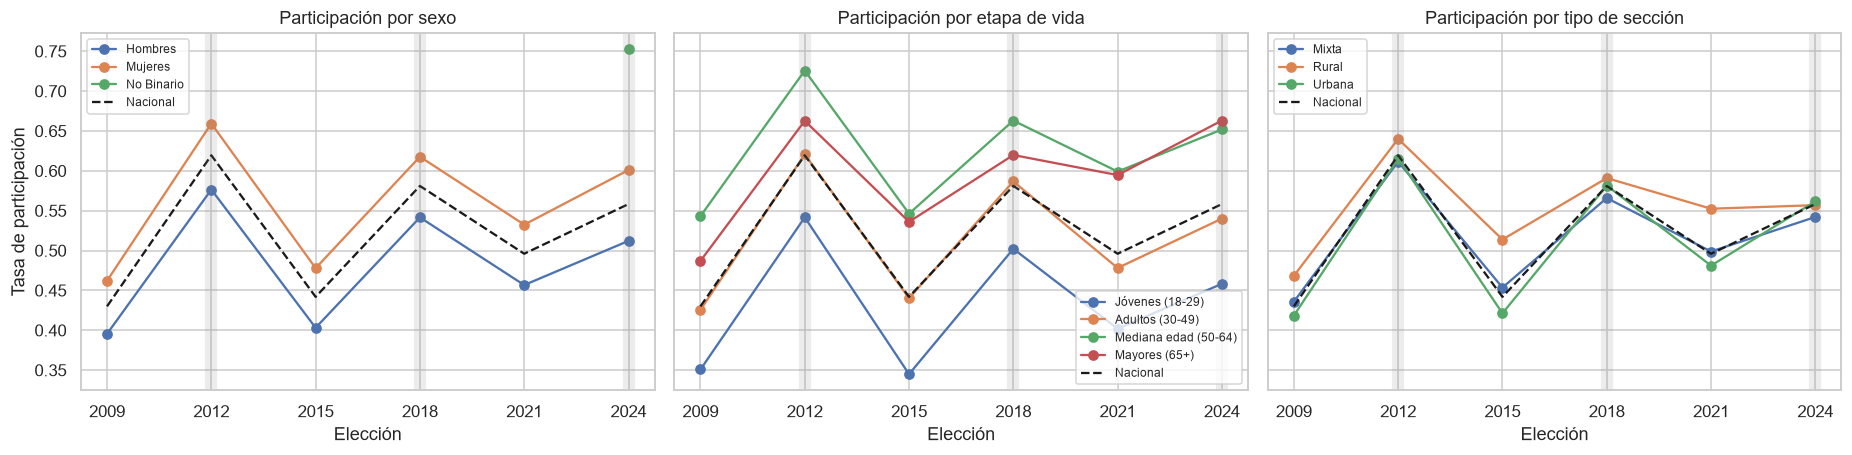

In [15]:
def tasa(d, por):
    g = d.groupby(por)[["participantes", "lista_nominal"]].sum()
    return (g["participantes"] / g["lista_nominal"]).rename("tasa")

df["ciclo_vida"] = df["grupo_edad"].map(U.edad_inferior).map(U.ciclo_vida)

# --- Participación nacional por elección ---
nac = tasa(df, "anio")
print(nac.round(3).to_frame().T)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), sharey=True)
for ax, (var, titulo) in zip(axes, [("sexo", "por sexo"), ("ciclo_vida", "por etapa de vida"), ("tipo_seccion", "por tipo de sección")]):
    t = tasa(df, ["anio", var]).unstack(var)
    if var == "ciclo_vida":
        t = t[[c for c in U.ORDEN_CICLO if c in t.columns]]
    t.plot(ax=ax, marker="o")
    ax.plot(nac.index, nac.values, "k--", label="Nacional")
    for a in U.ANIOS_PRES:
        ax.axvline(a, color="gray", alpha=.15, lw=8)   # franjas = elecciones presidenciales
    ax.set(title=f"Participación {titulo}", xlabel="Elección", xticks=U.ANIOS)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Tasa de participación")
plt.tight_layout(); plt.show()

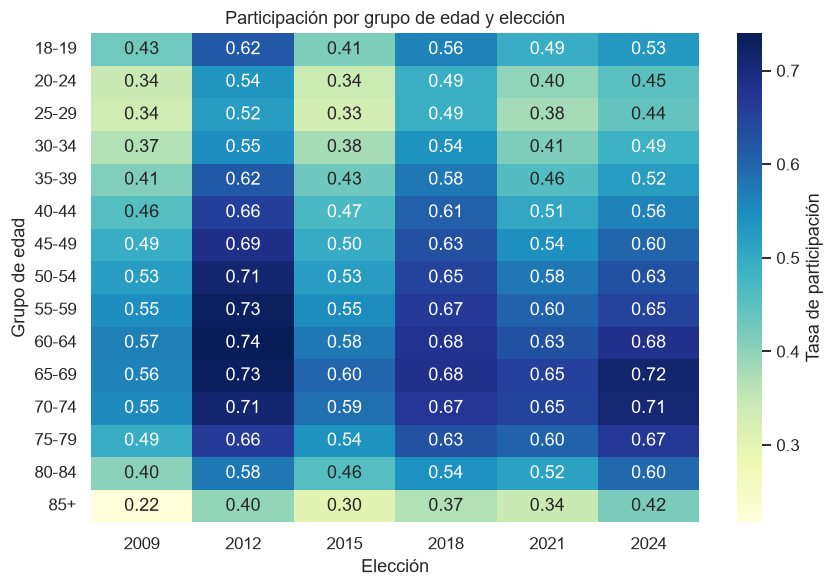

In [16]:
# Mapa de calor: tasa por grupo de edad x elección (¿se ve el efecto "presidencial vs intermedia"?)
orden = U.orden_grupos_edad(df["grupo_edad"])
m = tasa(df, ["grupo_edad", "anio"]).unstack("anio").loc[orden]
plt.figure(figsize=(8, 5.5))
sns.heatmap(m, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={"label": "Tasa de participación"})
plt.title("Participación por grupo de edad y elección"); plt.ylabel("Grupo de edad"); plt.xlabel("Elección")
plt.tight_layout(); plt.show()

In [17]:
# Brecha de participación entre sexos (mujeres - hombres), por elección
t = tasa(df, ["anio", "sexo"]).unstack("sexo")
if {"Hombres", "Mujeres"} <= set(t.columns):
    print("Brecha Mujeres - Hombres (puntos porcentuales):")
    print(((t["Mujeres"] - t["Hombres"]) * 100).round(2).to_frame("pp").T)

Brecha Mujeres - Hombres (puntos porcentuales):
anio  2009  2012  2015  2018  2021  2024
pp   6.660 8.290 7.470 7.610 7.580 8.890


## 4. Guardar la base limpia
Se guarda también la **fuente** (real/sintética) para que los notebooks siguientes te avisen si estás usando datos de prueba.

In [18]:
df.drop(columns=["ciclo_vida"]).to_csv(U.DIR_PROC / "ccpc_limpio.csv.gz", index=False)
(U.DIR_PROC / "FUENTE.txt").write_text(FUENTE)
print("Guardado:", U.DIR_PROC / "ccpc_limpio.csv.gz", "| fuente:", FUENTE)

Guardado: C:\Users\Pro12\Desktop\INE\data\processed\ccpc_limpio.csv.gz | fuente: REAL
